# Classical Machine Learning - Guided Scikit-learn Practice

**Goal:** move from paper intuition to real scikit-learn implementation.

Use the same clean dataset for regression, classification, clustering and PCA. The notebook is intentionally guided: every section tells you **what to calculate by hand first**, then gives the sklearn implementation so you can verify yourself.

### Main targets
- **Regression:** predict `Final_Marks`
- **Classification:** predict `Pass` (1 if Final_Marks >= 60, else 0)
- **Unsupervised:** ignore targets and discover structure from input features

> Important: never use `Final_Marks` as an input when predicting `Pass`, because that would leak the rule used to create the target.

## 0. Setup and sklearn mental model

Most estimators follow the same interface:

`model.fit(X_train, y_train)` -> learn from training data  
`model.predict(X_test)` -> make predictions  
`model.predict_proba(...)` -> probabilities for classifiers that support it  
`transform(...)` -> transform features for preprocessors such as scalers/PCA

We will use **80% train / 20% test**, `random_state=42` for reproducibility, and `stratify=y` for classification so both classes keep similar proportions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    silhouette_score
)

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (7, 5)


In [2]:
df = pd.read_csv('classical_ml_student_performance.csv')
print('Shape:', df.shape)
display(df.head())
print('\nPass balance:')
print(df['Pass'].value_counts(normalize=True).round(3))
display(df.describe().round(2))

Shape: (320, 9)


,Student_ID,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests,Final_Marks,Pass
0,S001,12.2,79.7,83.1,89.2,6.4,7,93.2,1
1,S002,11.8,55.7,30.0,77.9,6.4,6,61.8,1
2,S003,13.4,98.3,66.2,96.3,6.1,6,86.3,1
3,S004,9.0,95.4,70.5,86.5,5.5,6,64.9,1
4,S005,8.0,58.4,56.8,53.5,6.0,4,44.3,0



Pass balance:
Pass
1    0.538
0    0.462
Name: proportion, dtype: float64


,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests,Final_Marks,Pass
count,320.00,320.00,320.00,320.00,320.00,320.00,320.00,320.00
mean,7.71,73.82,65.40,70.27,6.63,4.77,59.78,0.54
std,3.28,13.09,14.42,14.91,0.93,2.56,17.63,0.50
min,1.00,40.00,30.00,30.00,4.50,0.00,20.00,0.00
25%,5.10,64.57,55.45,61.40,6.10,3.00,46.72,0.00
50%,7.80,74.20,65.55,71.50,6.60,5.00,61.10,1.00
75%,9.93,84.80,76.80,81.05,7.30,7.00,73.60,1.00
max,15.00,100.00,95.00,100.00,9.00,10.00,95.10,1.00


### Features we will use
All six predictors are numeric so you can focus on algorithms rather than encoding.

**Paper subset:** before each hand exercise, use the first 10 rows below. Do not judge model quality from these 10 rows; they are only for calculations.

In [3]:
feature_cols = ['Study_Hours','Attendance_pct','Previous_Marks','Assignment_Score','Sleep_Hours','Practice_Tests']
paper10 = df.loc[:9, ['Student_ID'] + feature_cols + ['Final_Marks','Pass']]
display(paper10)

,Student_ID,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests,Final_Marks,Pass
0,S001,12.2,79.7,83.1,89.2,6.4,7,93.2,1
1,S002,11.8,55.7,30.0,77.9,6.4,6,61.8,1
2,S003,13.4,98.3,66.2,96.3,6.1,6,86.3,1
3,S004,9.0,95.4,70.5,86.5,5.5,6,64.9,1
4,S005,8.0,58.4,56.8,53.5,6.0,4,44.3,0
5,S006,11.9,73.4,70.7,87.0,6.6,2,79.9,1
6,S007,12.7,84.8,74.3,79.0,7.5,10,77.3,1
7,S008,10.4,85.0,91.0,84.2,7.6,2,68.4,1
8,S009,4.6,60.3,47.2,50.8,6.5,1,38.2,0
9,S010,6.5,66.1,88.4,88.2,7.0,7,65.7,1


# Part A - Regression

Regression predicts a **continuous value**. We will predict `Final_Marks`.

Evaluation:
- **MAE**: average absolute error in marks; lower is better.
- **RMSE**: penalizes larger errors more strongly; lower is better.
- **R²**: fraction of variance explained; closer to 1 is better.

## 1. Simple Linear Regression

**Question:** Can Study_Hours alone predict Final_Marks?

### Paper first
Take the first 5 rows of `paper10`. Compute:
1. mean of x and y
2. slope `b1 = sum((x-xbar)(y-ybar)) / sum((x-xbar)^2)`
3. intercept `b0 = ybar - b1*xbar`
4. predict marks for 8 study hours

Then run the verification cell.

In [4]:
manual = paper10.iloc[:5]
x = manual['Study_Hours'].to_numpy()
y = manual['Final_Marks'].to_numpy()

x_bar, y_bar = x.mean(), y.mean()
b1 = np.sum((x-x_bar)*(y-y_bar)) / np.sum((x-x_bar)**2)
b0 = y_bar - b1*x_bar
manual_pred_8 = b0 + b1*8
print(f'Manual slope = {b1:.3f}')
print(f'Manual intercept = {b0:.3f}')
print(f'Manual prediction at 8 hours = {manual_pred_8:.2f}')

Manual slope = 7.115
Manual intercept = -7.309
Manual prediction at 8 hours = 49.61


### sklearn implementation
Use `LinearRegression()` with no special parameters initially. Important learned attributes: `coef_` and `intercept_`.

In [5]:
X_simple = df[['Study_Hours']]
y_reg = df['Final_Marks']

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_reg, test_size=0.20, random_state=42
)

simple_lr = LinearRegression()
simple_lr.fit(X_train_s, y_train_s)
y_pred_s = simple_lr.predict(X_test_s)

print('Coefficient:', simple_lr.coef_[0])
print('Intercept:', simple_lr.intercept_)
print('MAE:', mean_absolute_error(y_test_s, y_pred_s))
print('RMSE:', root_mean_squared_error(y_test_s, y_pred_s))
print('R²:', r2_score(y_test_s, y_pred_s))

Coefficient: 4.658451127716661
Intercept: 23.92131331141229
MAE: 6.701029473883294
RMSE: 8.423701234624717
R²: 0.7773437881376936


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


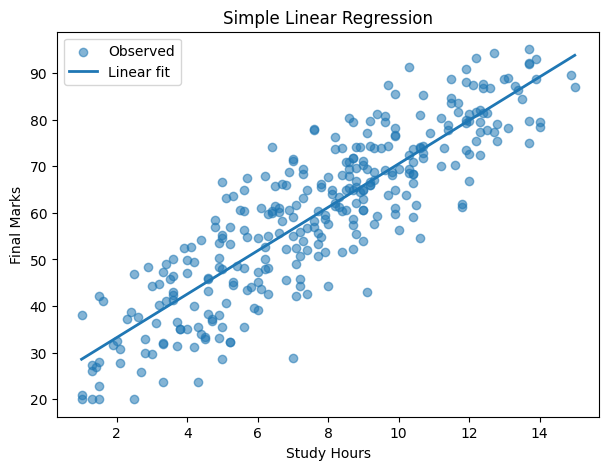

In [6]:
plt.scatter(df['Study_Hours'], df['Final_Marks'], alpha=0.55, label='Observed')
x_line = np.linspace(df['Study_Hours'].min(), df['Study_Hours'].max(), 100).reshape(-1,1)
plt.plot(x_line, simple_lr.predict(x_line), linewidth=2, label='Linear fit')
plt.xlabel('Study Hours')
plt.ylabel('Final Marks')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

## 2. Multiple Linear Regression

Now use all six predictors. `LinearRegression()` stays the same; only `X` changes.

### Paper idea
Do **not** solve six coefficients by hand. Instead, write the model form on paper:
`Final = b0 + b1*Study + b2*Attendance + ... + b6*PracticeTests`
Then interpret one fitted coefficient while holding all other variables constant.

In [7]:
X = df[feature_cols]
X_train, X_test, y_train, y_test = train_test_split(
    X, y_reg, test_size=0.20, random_state=42
)

multi_lr = LinearRegression()
multi_lr.fit(X_train, y_train)
y_pred_multi = multi_lr.predict(X_test)

coef_table = pd.DataFrame({'Feature': feature_cols, 'Coefficient': multi_lr.coef_})
display(coef_table.sort_values('Coefficient', key=abs, ascending=False))
print('Intercept:', round(multi_lr.intercept_, 3))
print('MAE:', round(mean_absolute_error(y_test, y_pred_multi), 3))
print('RMSE:', round(root_mean_squared_error(y_test, y_pred_multi), 3))
print('R²:', round(r2_score(y_test, y_pred_multi), 3))

,Feature,Coefficient
0,Study_Hours,2.783904
4,Sleep_Hours,0.805575
5,Practice_Tests,0.637448
3,Assignment_Score,0.228201
2,Previous_Marks,0.204492
1,Attendance_pct,0.169851


Intercept: -12.106
MAE: 5.237
RMSE: 6.336
R²: 0.874


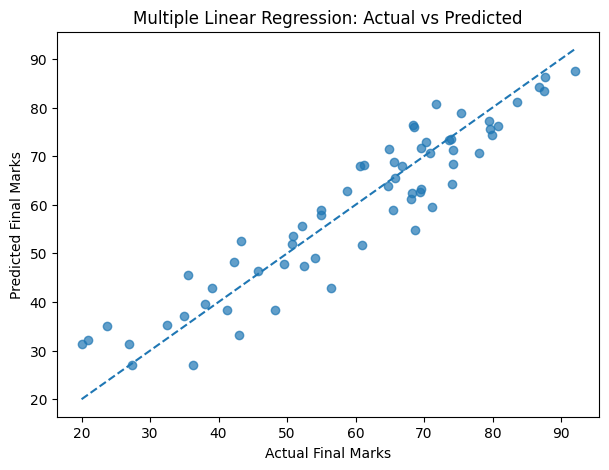

In [8]:
plt.scatter(y_test, y_pred_multi, alpha=0.7)
lims = [min(y_test.min(), y_pred_multi.min()), max(y_test.max(), y_pred_multi.max())]
plt.plot(lims, lims, '--')
plt.xlabel('Actual Final Marks')
plt.ylabel('Predicted Final Marks')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.show()

## 3. Polynomial Regression

Polynomial regression is still linear regression **in transformed features**. We will use Study_Hours -> `[x, x²]`.

Functions:
- `PolynomialFeatures(degree=2, include_bias=False)`
- `LinearRegression()`

### Paper first
For `x = 8`, write the transformed features `[8, 64]`. After fitting, the model has the form `b0 + b1*x + b2*x²`.

Important parameter: `degree`. Higher degree = more flexibility and more overfitting risk.

In [9]:
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly_model.fit(X_train_s, y_train_s)
y_pred_poly = poly_model.predict(X_test_s)

print('MAE:', round(mean_absolute_error(y_test_s, y_pred_poly), 3))
print('RMSE:', round(root_mean_squared_error(y_test_s, y_pred_poly), 3))
print('R²:', round(r2_score(y_test_s, y_pred_poly), 3))

MAE: 6.601
RMSE: 8.291
R²: 0.784


/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


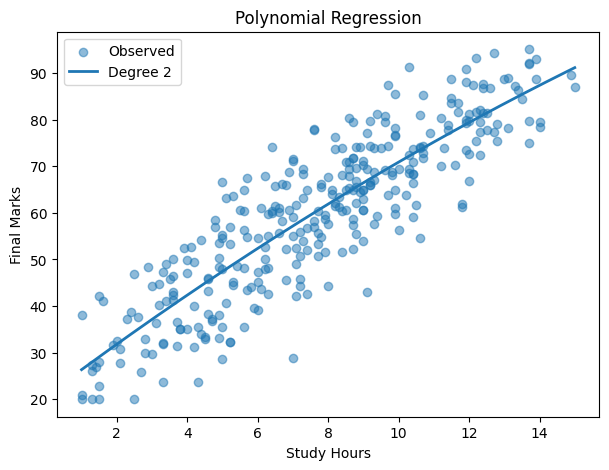

In [10]:
plt.scatter(df['Study_Hours'], df['Final_Marks'], alpha=0.5, label='Observed')
x_line = np.linspace(df['Study_Hours'].min(), df['Study_Hours'].max(), 200).reshape(-1,1)
plt.plot(x_line, poly_model.predict(x_line), linewidth=2, label='Degree 2')
plt.xlabel('Study Hours')
plt.ylabel('Final Marks')
plt.title('Polynomial Regression')
plt.legend()
plt.show()

## 4. Ridge and Lasso Regression

Both add a penalty to reduce overly large coefficients.

- **Ridge** uses L2 penalty; tends to shrink coefficients.
- **Lasso** uses L1 penalty; can drive some coefficients to exactly zero.

Use scaling because regularization depends on coefficient magnitude.

Functions/parameters:
- `StandardScaler()`
- `Ridge(alpha=1.0)`
- `Lasso(alpha=0.10, max_iter=10000)`

`alpha`: regularization strength. Larger alpha = stronger shrinkage.

### Paper task
You do **not** solve Ridge/Lasso optimization manually. Write why an unscaled feature measured 0-100 could otherwise be penalized differently from a feature measured 0-10.

In [11]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
lasso = make_pipeline(StandardScaler(), Lasso(alpha=0.10, max_iter=10000))

regression_models = {
    'Multiple Linear': multi_lr,
    'Ridge': ridge,
    'Lasso': lasso,
}

reg_results = []
for name, model in regression_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    reg_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': root_mean_squared_error(y_test, pred),
        'R2': r2_score(y_test, pred)
    })

display(pd.DataFrame(reg_results).round(3).sort_values('RMSE'))

,Model,MAE,RMSE,R2
2,Lasso,5.260,6.335,0.874
0,Multiple Linear,5.237,6.336,0.874
1,Ridge,5.239,6.343,0.874


In [12]:
ridge_coef = ridge.named_steps['ridge'].coef_
lasso_coef = lasso.named_steps['lasso'].coef_
coef_compare = pd.DataFrame({
    'Feature': feature_cols,
    'Ridge_coef_scaled': ridge_coef,
    'Lasso_coef_scaled': lasso_coef
})
display(coef_compare.round(3))

,Feature,Ridge_coef_scaled,Lasso_coef_scaled
0,Study_Hours,9.088,9.135
1,Attendance_pct,2.197,2.150
2,Previous_Marks,2.878,2.865
3,Assignment_Score,3.362,3.319
4,Sleep_Hours,0.761,0.685
5,Practice_Tests,1.673,1.624


# Part B - Classification

Classification predicts a category. Here `Pass` is binary.

We use `stratify=y` in `train_test_split()` so train/test keep the class balance.

Metrics:
- Accuracy: overall fraction correct
- Precision: among predicted passes, how many really passed?
- Recall: among actual passes, how many did we find?
- F1: balance of precision and recall
- Confusion matrix: TN, FP, FN, TP

In [13]:
y_clf = df['Pass']
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

def evaluate_classifier(name, model):
    model.fit(X_train_c, y_train_c)
    pred = model.predict(X_test_c)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test_c, pred),
        'Precision': precision_score(y_test_c, pred, zero_division=0),
        'Recall': recall_score(y_test_c, pred, zero_division=0),
        'F1': f1_score(y_test_c, pred, zero_division=0),
    }, pred


## 5. Logistic Regression

Despite the name, this is a **classifier**. It learns a linear score `z`, then maps it to a probability with the sigmoid.

Use:
`make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))`

Important parameters:
- `C`: inverse regularization strength; smaller C = stronger regularization
- `max_iter`: optimization limit
- `class_weight`: useful later for imbalanced classes

### Paper first
Calculate sigmoid for `z=1`: `1/(1+e^-1)`. With threshold 0.5, decide the class.

{'Model': 'Logistic Regression', 'Accuracy': 0.90625, 'Precision': 0.9666666666666667, 'Recall': 0.8529411764705882, 'F1': 0.90625}

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.97      0.91        30
           1       0.97      0.85      0.91        34

    accuracy                           0.91        64
   macro avg       0.91      0.91      0.91        64
weighted avg       0.91      0.91      0.91        64



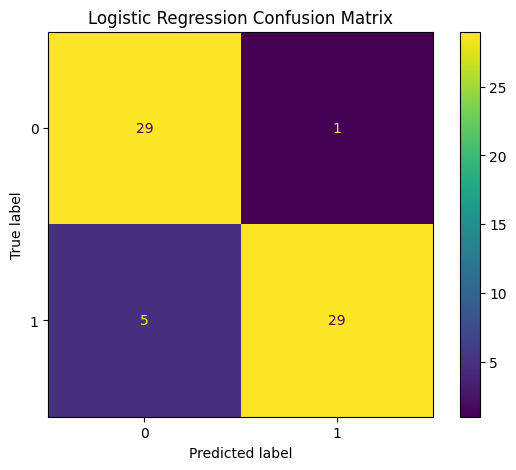

In [14]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, max_iter=1000, random_state=42)
)
log_result, log_pred = evaluate_classifier('Logistic Regression', log_reg)
print(log_result)
print()
print('Classification report:')
print(classification_report(y_test_c, log_pred))
ConfusionMatrixDisplay.from_predictions(y_test_c, log_pred)
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [15]:
sample = X_test_c.iloc[[0]]
prob = log_reg.predict_proba(sample)[0,1]
print('Sample features:')
display(sample)
print(f'Predicted probability of Pass = {prob:.3f}')
print('Predicted class =', log_reg.predict(sample)[0])

Sample features:


,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests
299,9.0,78.3,47.9,73.6,7.0,6


Predicted probability of Pass = 0.715
Predicted class = 1


## 6. K-Nearest Neighbors (KNN)

KNN predicts from nearby training samples. Distance-based algorithms are sensitive to feature scale, so we use `StandardScaler()`.

Use:
`KNeighborsClassifier(n_neighbors=7, weights='uniform')`

Important parameters:
- `n_neighbors` (k)
- `weights`: `'uniform'` or `'distance'`
- `metric`: default Minkowski; with p=2 this is Euclidean distance

### Paper first
Take 5 rows and only two features: Study_Hours and Attendance. Standardize conceptually, choose one query student, calculate Euclidean distances, choose k=3 and majority vote.

In [16]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=7, weights='uniform')
)
knn_result, knn_pred = evaluate_classifier('KNN', knn)
print(knn_result)

{'Model': 'KNN', 'Accuracy': 0.96875, 'Precision': 1.0, 'Recall': 0.9411764705882353, 'F1': 0.9696969696969697}


## 7. Decision Tree

A tree recursively chooses feature thresholds that make child nodes purer.

Use:
`DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)`

Important parameters:
- `criterion`: `'gini'` or `'entropy'`
- `max_depth`: limits complexity
- `min_samples_split`, `min_samples_leaf`: regularize the tree

### Paper first
For a binary node with 6 Pass and 4 Fail, compute Gini = `1 - p(pass)^2 - p(fail)^2`. Then imagine splitting on Attendance and compare child purity.

{'Model': 'Decision Tree', 'Accuracy': 0.90625, 'Precision': 0.9375, 'Recall': 0.8823529411764706, 'F1': 0.9090909090909091}


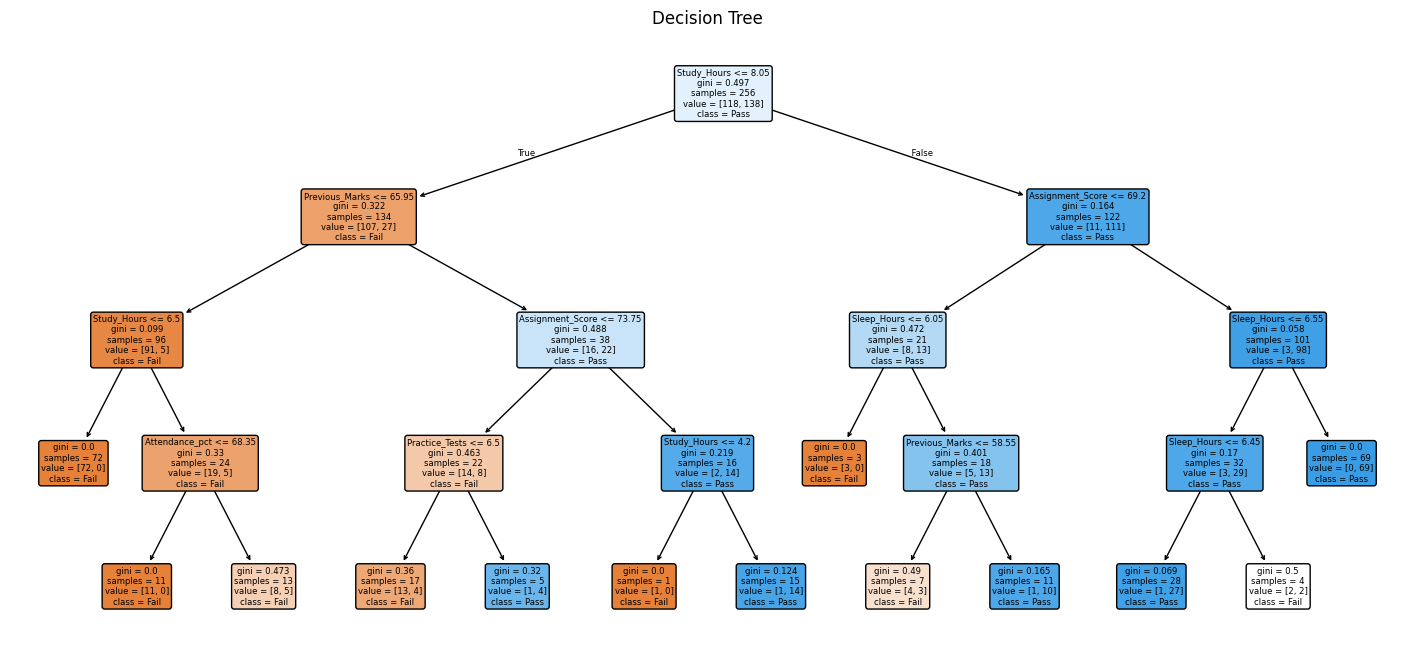

In [17]:
tree = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
tree_result, tree_pred = evaluate_classifier('Decision Tree', tree)
print(tree_result)

plt.figure(figsize=(18,8))
plot_tree(tree, feature_names=feature_cols, class_names=['Fail','Pass'], filled=True, rounded=True)
plt.title('Decision Tree')
plt.show()

## 8. Gaussian Naive Bayes

Naive Bayes uses Bayes' rule and assumes features are conditionally independent given the class. `GaussianNB` models each numeric feature with a Gaussian distribution per class.

Use: `GaussianNB(var_smoothing=1e-9)`

Important parameter: `var_smoothing` for numerical stability. Scaling is not required in the same way as KNN/SVM.

### Paper first
From the 10-row subset, separate Pass=0 and Pass=1. For `Study_Hours`, compute class means. This is part of what GaussianNB learns.

In [18]:
nb_model = GaussianNB(var_smoothing=1e-9)
nb_result, nb_pred = evaluate_classifier('Gaussian NB', nb_model)
print(nb_result)

{'Model': 'Gaussian NB', 'Accuracy': 0.90625, 'Precision': 0.9666666666666667, 'Recall': 0.8529411764705882, 'F1': 0.90625}


## 9. Support Vector Machine (SVM)

SVM tries to create a boundary with a large margin. With the RBF kernel it can learn nonlinear boundaries. Scale features first.

Use:
`SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)`

Important parameters:
- `C`: penalty for misclassification; larger = fit training data more aggressively
- `kernel`: `'linear'`, `'rbf'`, etc.
- `gamma`: reach of each training example for RBF

### Paper task
Draw two classes on a 2D plane and sketch a separating line plus two margin lines. The closest points are the support vectors. Do not solve the optimization by hand.

In [19]:
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)
)
svm_result, svm_pred = evaluate_classifier('SVM (RBF)', svm)
print(svm_result)

{'Model': 'SVM (RBF)', 'Accuracy': 0.9375, 'Precision': 0.9411764705882353, 'Recall': 0.9411764705882353, 'F1': 0.9411764705882353}


## 10. Random Forest

Random Forest is **bagging**: many randomized decision trees vote together. It usually reduces the variance of one tree. Scaling is normally unnecessary.

Use:
`RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, n_jobs=-1)`

Important parameters:
- `n_estimators`: number of trees
- `max_depth`
- `max_features`: features considered at each split
- `min_samples_leaf`

### Paper task
Do not build 200 trees by hand. Draw 3 small trees trained on different bootstrap samples and show majority voting for one student.

{'Model': 'Random Forest', 'Accuracy': 0.953125, 'Precision': 0.9696969696969697, 'Recall': 0.9411764705882353, 'F1': 0.9552238805970149}


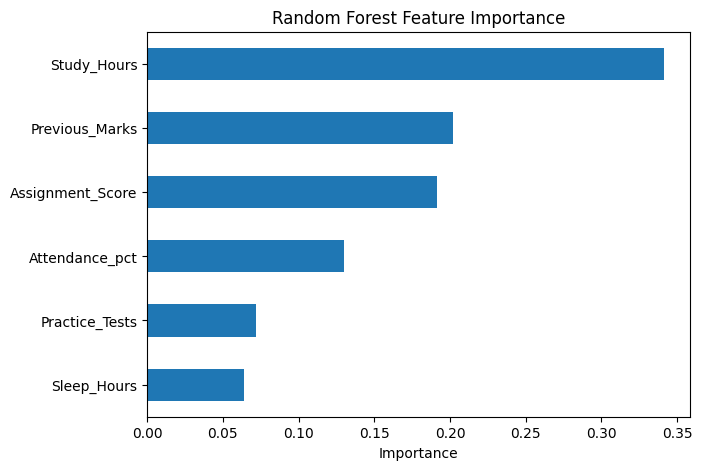

In [20]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=6, random_state=42, n_jobs=-1
)
rf_result, rf_pred = evaluate_classifier('Random Forest', rf)
print(rf_result)

importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
importance.plot(kind='barh')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.show()

## 11. Gradient Boosting

Boosting builds weak trees **sequentially**, where later trees focus on errors from earlier trees.

Use:
`GradientBoostingClassifier(n_estimators=120, learning_rate=0.05, max_depth=2, random_state=42)`

Important parameters:
- `n_estimators`: number of boosting stages
- `learning_rate`: size of each correction
- `max_depth`: complexity of each weak tree
- `subsample`: <1 adds stochasticity

### Paper task
Conceptually track 3 stages: initial prediction -> errors -> small tree corrects errors -> new prediction. No full gradient derivation needed yet.

In [21]:
gb = GradientBoostingClassifier(
    n_estimators=120, learning_rate=0.05, max_depth=2, random_state=42
)
gb_result, gb_pred = evaluate_classifier('Gradient Boosting', gb)
print(gb_result)

{'Model': 'Gradient Boosting', 'Accuracy': 0.9375, 'Precision': 0.96875, 'Recall': 0.9117647058823529, 'F1': 0.9393939393939394}


## 12. Compare Classifiers

A single train/test split is useful, but we will also add **5-fold stratified cross-validation** afterward for a more stable comparison.

In [22]:
classification_models = {
    'Logistic Regression': log_reg,
    'KNN': knn,
    'Decision Tree': tree,
    'Gaussian NB': nb_model,
    'SVM (RBF)': svm,
    'Random Forest': rf,
    'Gradient Boosting': gb,
}

rows=[]
for name, model in classification_models.items():
    result, _ = evaluate_classifier(name, model)
    rows.append(result)
clf_results = pd.DataFrame(rows).sort_values('F1', ascending=False)
display(clf_results.round(3))

,Model,Accuracy,Precision,Recall,F1
1,KNN,0.969,1.000,0.941,0.970
5,Random Forest,0.953,0.970,0.941,0.955
4,SVM (RBF),0.938,0.941,0.941,0.941
6,Gradient Boosting,0.938,0.969,0.912,0.939
2,Decision Tree,0.906,0.938,0.882,0.909
0,Logistic Regression,0.906,0.967,0.853,0.906
3,Gaussian NB,0.906,0.967,0.853,0.906


# Part C - Unsupervised Learning

## 13. K-Means Clustering

K-Means has no target `y`. It repeatedly:
1. assigns each point to nearest centroid
2. recomputes centroids
3. repeats until stable

Scale first because distances drive the algorithm.

Use:
`KMeans(n_clusters=3, random_state=42, n_init='auto')`

Important parameters:
- `n_clusters`
- `init`
- `n_init`
- `max_iter`

### Paper first
Using only Study_Hours and Attendance for 6 selected students, choose two or three starting centroids, calculate Euclidean distances, assign clusters, then compute one updated centroid.

In [23]:
scaler_unsup = StandardScaler()
X_scaled = scaler_unsup.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
clusters = kmeans.fit_predict(X_scaled)

df_clustered = df.copy()
df_clustered['Cluster'] = clusters
print('Silhouette score:', round(silhouette_score(X_scaled, clusters), 3))
display(df_clustered.groupby('Cluster')[feature_cols + ['Final_Marks','Pass']].mean().round(2))

Silhouette score: 0.219


,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests,Final_Marks,Pass
Cluster,,,,,,,,
0,7.85,73.97,63.28,72.33,6.48,4.41,60.21,0.56
1,10.55,85.61,79.41,81.24,7.10,7.16,76.80,0.96
2,4.27,60.13,51.86,55.26,6.28,2.46,39.76,0.02


## 14. Principal Component Analysis (PCA)

PCA is dimensionality reduction, not a predictor. It finds directions that capture maximum variance. Scale first.

Use: `PCA(n_components=2)`

Important parameters:
- `n_components`: number of components to keep
- `whiten`: usually leave False while learning

Attributes:
- `components_`
- `explained_variance_ratio_`

### Paper first
For two features only, write the steps: center -> covariance matrix -> eigenvectors/eigenvalues -> project. You do not need to solve a 6x6 eigenproblem by hand.

In [24]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print('Explained variance ratio:', np.round(pca.explained_variance_ratio_, 3))
print('Total explained by 2 PCs:', round(pca.explained_variance_ratio_.sum(), 3))

pca_df = pd.DataFrame(X_pca, columns=['PC1','PC2'])
pca_df['Pass'] = df['Pass'].to_numpy()
pca_df['Cluster'] = clusters
display(pca_df.head())

Explained variance ratio: [0.561 0.148]
Total explained by 2 PCs: 0.709


,PC1,PC2,Pass,Cluster
0,2.202291,-0.787443,1,1
1,-0.762531,-0.586475,1,0
2,2.436307,-1.234048,1,1
3,1.430645,-1.593135,1,1
4,-1.503241,-0.272045,0,2


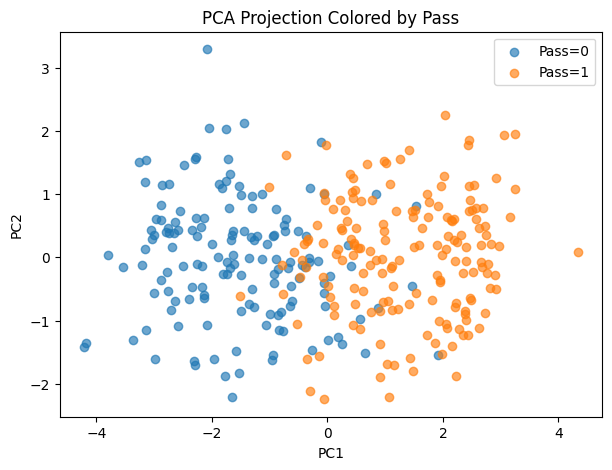

In [25]:
for label in sorted(pca_df['Pass'].unique()):
    part = pca_df[pca_df['Pass']==label]
    plt.scatter(part['PC1'], part['PC2'], alpha=0.65, label=f'Pass={label}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Projection Colored by Pass')
plt.legend()
plt.show()

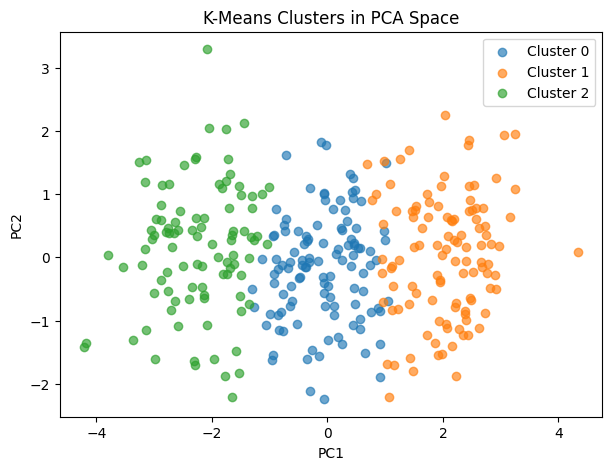

In [26]:
for cluster_id in sorted(pca_df['Cluster'].unique()):
    part = pca_df[pca_df['Cluster']==cluster_id]
    plt.scatter(part['PC1'], part['PC2'], alpha=0.65, label=f'Cluster {cluster_id}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('K-Means Clusters in PCA Space')
plt.legend()
plt.show()

# Part D - Better Evaluation with Cross-Validation

A single split can be lucky or unlucky. Cross-validation repeats training/testing on multiple folds.

For regression use shuffled `KFold`. For classification use `StratifiedKFold` so class proportions are preserved.

Remember: cross-validation evaluates the **whole pipeline**, so scaling must stay inside a pipeline to prevent leakage.

In [27]:
reg_cv = KFold(n_splits=5, shuffle=True, random_state=42)
reg_cv_models = {
    'Linear': LinearRegression(),
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=0.10, max_iter=10000)),
}
reg_cv_rows=[]
for name, model in reg_cv_models.items():
    r2_scores = cross_val_score(model, X, y_reg, cv=reg_cv, scoring='r2')
    mae_scores = -cross_val_score(model, X, y_reg, cv=reg_cv, scoring='neg_mean_absolute_error')
    reg_cv_rows.append({
        'Model': name,
        'Mean CV R2': r2_scores.mean(),
        'SD R2': r2_scores.std(),
        'Mean CV MAE': mae_scores.mean()
    })
display(pd.DataFrame(reg_cv_rows).round(3))

,Model,Mean CV R2,SD R2,Mean CV MAE
0,Linear,0.86,0.042,5.116
1,Ridge,0.86,0.042,5.112
2,Lasso,0.86,0.042,5.122


In [28]:
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_cv_rows=[]
for name, model in classification_models.items():
    acc = cross_val_score(model, X, y_clf, cv=clf_cv, scoring='accuracy')
    f1 = cross_val_score(model, X, y_clf, cv=clf_cv, scoring='f1')
    clf_cv_rows.append({
        'Model': name,
        'Mean CV Accuracy': acc.mean(),
        'SD Accuracy': acc.std(),
        'Mean CV F1': f1.mean()
    })
display(pd.DataFrame(clf_cv_rows).round(3).sort_values('Mean CV F1', ascending=False))

,Model,Mean CV Accuracy,SD Accuracy,Mean CV F1
4,SVM (RBF),0.903,0.023,0.913
1,KNN,0.903,0.033,0.912
5,Random Forest,0.900,0.023,0.909
3,Gaussian NB,0.900,0.031,0.908
0,Logistic Regression,0.897,0.016,0.906
6,Gradient Boosting,0.897,0.031,0.903
2,Decision Tree,0.866,0.032,0.873


# Part E - Scaling and Parameter Cheat Sheet

| Model | Scale? | First parameters to experiment with |
|---|---|---|
| Linear Regression | Usually no | none initially |
| Polynomial | depends; yes if regularized | `degree` |
| Ridge | **Yes** | `alpha` |
| Lasso | **Yes** | `alpha`, `max_iter` |
| Logistic Regression | **Usually yes** | `C`, `class_weight`, `max_iter` |
| KNN | **Yes** | `n_neighbors`, `weights`, `metric` |
| Decision Tree | No | `max_depth`, `min_samples_leaf`, `criterion` |
| Gaussian NB | Not required | `var_smoothing` |
| SVM | **Yes** | `C`, `kernel`, `gamma` |
| Random Forest | No | `n_estimators`, `max_depth`, `max_features` |
| Gradient Boosting | No | `n_estimators`, `learning_rate`, `max_depth` |
| K-Means | **Yes** | `n_clusters`, `n_init` |
| PCA | **Usually yes** | `n_components` |

# Final Practice - Do This Without Copying the Above Cells

1. Pick a new `random_state` and repeat one regression + one classification model.
2. For KNN, compare `k = 3, 5, 7, 11`. Explain underfitting vs overfitting.
3. For Decision Tree, compare `max_depth = 2, 4, None`; record train and test accuracy.
4. For SVM, compare linear vs RBF kernels.
5. For Random Forest, compare 50 vs 200 trees. Does performance stabilize?
6. For Gradient Boosting, compare `learning_rate=0.1` vs `0.05` while adjusting `n_estimators`.
7. For Ridge/Lasso, compare alpha values `[0.01, 0.1, 1, 10]`. Watch coefficient shrinkage.
8. For K-Means, try k=2..6 and calculate silhouette score.
9. For PCA, find how many components are needed to explain at least 90% of variance.
10. Write a one-page model-selection conclusion: which regression model and classifier would you keep, and why?

### You are ready to move on when you can answer:
- Why do we split before scaling?
- Why does KNN need scaling but trees usually do not?
- Why is test performance more important than training performance?
- When would recall matter more than accuracy?
- What is the difference between bagging (Random Forest) and boosting?
- What does `alpha` mean in Ridge/Lasso?
- Why can polynomial degree overfit?
- Why is PCA not a classifier?